# Tutorial 1: Analyze 10x Visium DLPFC dataset

In this tutorial, we demonstrate how to apply Redex to 10x Visium spatial transcriptomics data for spatial domain identification. We take the human dorsolateral prefrontal cortex (DLPFC) dataset as an example.

The DLPFC dataset contains 12 tissue sections, with manually annotated cortical layers (Layer 1–6 and white matter) serving as ground truth. Here we use section **151509** (7 clusters) for demonstration.

DLPFC data  should be placed under `./DLPFC/`.

## Loading packages

In [ ]:
# Installed package imports
import os
import scanpy as sc
import pandas as pd
import method
import Redex
from utils import clustering, evaluate, plot_spatial, plot_umap, plot_paga

os.environ['R_HOME'] = '/home/user/anaconda3/envs/redex/lib/R'

## Configuration

In [2]:
DATA_ROOT = './DLPFC'
RESULT_ROOT = './results/DLPFC151509'
DATASETS = {  '151509': 7,}


## Step 1: Gene Selection (Skip if the gene set already exists.)
Redex performs SVF selection module by computing the R_g score across multiple expression thresholds (25th, 50th, 75th percentiles) and merging the results.

In [3]:
for dataset in DATASETS:
    save_dir = os.path.join(RESULT_ROOT, dataset)
    gene_result_file = os.path.join(save_dir, 'three_top_rg-results_df.csv')

    if os.path.exists(gene_result_file):
        print(f"[Skip] Gene selection for {dataset} — {gene_result_file} already exists.")
        continue

    print(f"\n{'='*50}")
    print(f"Gene selection for {dataset}")
    print(f"{'='*50}")


    data_path = os.path.join(DATA_ROOT, dataset)
    save_dir = os.path.join(RESULT_ROOT, dataset)
    os.makedirs(save_dir, exist_ok=True)

    adata = sc.read_visium(data_path, count_file='filtered_feature_bc_matrix.h5', load_images=True)
    adata = method.preprocess_adata(adata, min_cells=20)
    neighbors = method.compute_neighbors(adata, k_neighbors=6)

    results_dict = {}
    for thre in [25, 50, 75]:
        gene_groups = method.compute_gene_groups(adata, exp_thre=thre, num_workers=1)
        W_gs = method.compute_weight_matrices(adata, neighbors, num_workers=1)
        results, R_g_values = method.compute_r_values(adata, W_gs, num_workers=1)
        results_dict[thre] = results

        # Save individual threshold results
        pd.DataFrame(results).to_csv(os.path.join(save_dir, f'results_{thre}.csv'), index=False)

    # Merge and save
    results_df = method.merge_files_and_compute_max(results_dict)
    results_df.to_csv(os.path.join(save_dir, 'three_top_rg-results_df.csv'), index=False)
    print(f"Gene selection results saved to {save_dir}")



Gene selection for 151509


D:\Users\jtyu\software\Anaconda\envs\redex\lib\site-packages\anndata\_core\anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
d:\users\jtyu\新建文件夹\new model with new gene combine\redex2\src\method.py:18: RuntimeWarning: divide by zero encountered in true_divide
  scale = np.where(diff != 0, (feature_range[1] - feature_range[0]) / diff, 0)
Computing gene groups: 100%|███████████████████████████████████████████████████| 14574/14574 [00:06<00:00, 2369.15it/s]
d:\users\jtyu\新建文件夹\new model with new gene combine\redex2\src\method.py:98: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['L_g'] = adata.var.index.map(lambda x: results[x]['L_g'] if x in results else [])
Computing R values: 100%|███████████████████████████████████████████████████████| 14574/14574 [01:11<00:00, 202.63it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|███████████████████████████████████████████████████████| 14574/14574 [01:11<00:00, 203.56it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|███████████████████████████████████████████████████████| 14574/14574 [01:13<00:00, 199.23it/s]


 R_g =A_g * B_g * C_g 
Gene selection results saved to ./results/DLPFC151509\151509


## Step 2: Model Training
After gene selection, we train the Redex model using the selected spatially variable genes.


In [4]:
for dataset, n_clusters in DATASETS.items():
    print(f"\n{'='*50}")
    print(f"Processing {dataset} (n_clusters={n_clusters})")
    print(f"{'='*50}")
    data_path = os.path.join(DATA_ROOT, dataset)
    gene_path = os.path.join(RESULT_ROOT, dataset)
    save_dir = os.path.join(RESULT_ROOT, dataset)
    os.makedirs(save_dir, exist_ok=True)
    
    # Load data
    adata = sc.read_visium(data_path, count_file='filtered_feature_bc_matrix.h5', load_images=True)
    adata.var_names_make_unique()
    
    # Train model
    model = Redex.Redex(adata, dataset, gene_path)
    adata = model.train()
    


Processing 151509 (n_clusters=7)


D:\Users\jtyu\software\Anaconda\envs\redex\lib\site-packages\anndata\_core\anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


self.der 1e-05
self.alpha 9
self.beta 1
processed 151509 our gene 3000
Begin to train ST data...


100%|████████████████████████████████████████████████████████████████████████████████| 600/600 [00:59<00:00, 10.01it/s]

Optimization finished for ST data!


## Step 3: Spatial Clustering
After model training, we apply mclust for spatial clustering with domain refinement.

In [ ]:
clustering(adata, n_clusters, radius=50, method='mclust', refinement=True)


R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.0.0
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


## Step 4: Evaluation
We evaluate the clustering performance using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) against the manual annotation.


In [6]:
df_meta = pd.read_csv(os.path.join(data_path, 'metadata.tsv'), sep='\t')
adata.obs['ground_truth'] = df_meta['layer_guess'].values
adata, ari, nmi = evaluate(adata, pred_key='domain', truth_key='ground_truth')




ARI = 0.5685
NMI = 0.6974


## Step 5: Visualization
Spatial domain plot

[Spatial plot] figsize=(3, 3), spot_size=100
Saved: ./results/DLPFC151509\151509\151509_spatial_domain.pdf


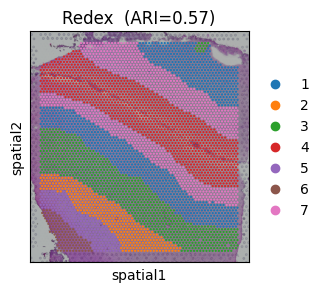

D:\Users\jtyu\software\Anaconda\envs\redex\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
D:\Users\jtyu\software\Anaconda\envs\redex\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


Saved: ./results/DLPFC151509\151509\151509_umap_domain.pdf


<Figure size 300x300 with 0 Axes>

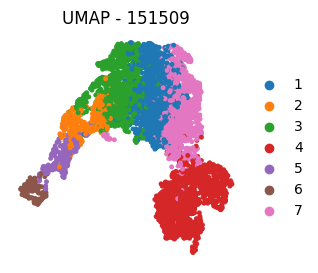

Saved: ./results/DLPFC151509\151509\151509_paga.pdf


<Figure size 300x300 with 0 Axes>

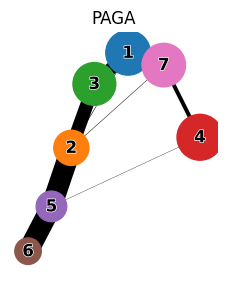

In [ ]:
plot_spatial(adata, 'domain',title=f'Redex  (ARI={ari:.2f})',
              save_path=os.path.join(save_dir, f'{dataset}_spatial_domain.pdf'))

plot_umap(adata, 'domain', title=f'UMAP - {dataset}',
          save_path=os.path.join(save_dir, f'{dataset}_umap_domain.pdf'))

plot_paga(adata, 'domain',
          save_path=os.path.join(save_dir, f'{dataset}_paga.pdf'))
